In [ ]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart


# 2. Иерархия: структура и простые методы

**Сквозной вопрос блока:** прогнозы уровней не складываются — как сделать их согласованными и при этом точнее?

В этом ноутбуке:
- мотивация: независимые прогнозы уровней не складываются;
- иерархическая и групповая структура, сборка иерархии через `aggregate()`, S-матрица;
- базовые прогнозы AutoETS по всем 89 рядам и мера несогласованности;
- bottom-up, top-down (три способа долей), middle-out;
- единая формула $\tilde y = S G \hat y$: BU и TD руками и сверка с `HierarchicalReconciliation`;
- сравнение методов по уровням иерархии.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsforecast import StatsForecast
from statsforecast.models import AutoETS
from hierarchicalforecast.utils import aggregate, HierarchicalPlot, is_strictly_hierarchical
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.methods import BottomUp, TopDown, MiddleOut
from hierarchicalforecast.evaluation import evaluate
from utilsforecast.losses import mase

plt.rcParams['figure.figsize'] = (12, 4)

H = 8  # горизонт: 8 кварталов

## 0. Данные и мотивация

TourismSmall — число ночей, проведённых туристами в Австралии, по кварталам 1998–2006 (36 точек).
Ряды названы `штат-цель-зона`: цель поездки `hol / vfr / bus / oth` (отдых / к родственникам / бизнес / прочее),
зона `city / noncity`. Агрегаты уже лежат в файле, но для сборки иерархии нам нужен только нижний уровень.

In [2]:
wide = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/hierarchical/TourismSmall/data.csv', index_col=0, parse_dates=True)
bottom_cols = [c for c in wide.columns if c.count('-') == 2]

print(f'Всего рядов: {wide.shape[1]}, нижних: {len(bottom_cols)}, точек: {len(wide)}')
print(f'Период: {wide.index.min().date()} — {wide.index.max().date()}')

Всего рядов: 89, нижних: 56, точек: 36
Период: 1998-03-31 — 2006-12-31


Спрогнозируем независимо общий ряд и четыре ряда по целям поездки — и сложим.

In [3]:
top = (wide[['total', 'hol', 'vfr', 'bus', 'oth']]
       .rename_axis('ds').reset_index()
       .melt('ds', var_name='unique_id', value_name='y'))

sf_top = StatsForecast(models=[AutoETS(season_length=4)], freq='QE', n_jobs=1)
fc_top = sf_top.forecast(df=top, h=H).pivot(index='ds', columns='unique_id', values='AutoETS')

check = pd.DataFrame({
    'total': fc_top['total'],
    'hol+vfr+bus+oth': fc_top[['hol', 'vfr', 'bus', 'oth']].sum(axis=1),
})
check['расхождение, %'] = 100 * (check['total'] - check['hol+vfr+bus+oth']) / check['total']
check.round(1)

,total,hol+vfr+bus+oth,"расхождение, %"
ds,,,
2007-03-31,82548.101562,82889.000000,-0.4
2007-06-30,63694.300781,63951.300781,-0.4
2007-09-30,69228.601562,69425.296875,-0.3
2007-12-31,68779.101562,68930.296875,-0.2
2008-03-31,82548.101562,82744.203125,-0.2
2008-06-30,63694.300781,63790.398438,-0.2
2008-09-30,69228.601562,69241.601562,-0.0
2008-12-31,68779.101562,68755.398438,0.0


Сумма прогнозов по целям не равна прогнозу total. Пока расхождение — доли процента, но ниже по иерархии
оно растёт (посчитаем в разделе 2). Бюджет компании (total) и планы отделов (по целям) не сходятся —
такие прогнозы нельзя использовать вместе. Нужны **согласованные** (coherent) прогнозы.

## 1. Структура иерархии

- **Иерархическая** структура — дерево: каждый ряд входит ровно в один ряд уровнем выше
  (total → цель → штат×цель → city/noncity).
- **Групповая** структура — несколько способов разрезать один и тот же низ (по цели и по штату одновременно):
  нижний ряд входит в несколько агрегатов одного уровня, дерева уже нет.

`aggregate()` строит все агрегаты по нижнему уровню. Аргумент `spec` — список уровней сверху вниз.

In [4]:
bottom = (wide[bottom_cols]
          .rename_axis('ds').reset_index()
          .melt('ds', var_name='series', value_name='y'))
bottom[['state', 'purpose', 'area']] = bottom['series'].str.split('-', expand=True)
bottom['total'] = 'total'
bottom.head()

,ds,series,y,state,purpose,area,total
0,1998-03-31,nsw-hol-city,3096,nsw,hol,city,total
1,1998-06-30,nsw-hol-city,1479,nsw,hol,city,total
2,1998-09-30,nsw-hol-city,1609,nsw,hol,city,total
3,1998-12-31,nsw-hol-city,1520,nsw,hol,city,total
4,1999-03-31,nsw-hol-city,1958,nsw,hol,city,total


In [5]:
spec = [
    ['total'],
    ['total', 'purpose'],
    ['total', 'purpose', 'state'],
    ['total', 'purpose', 'state', 'area'],
]
Y_df, S_df, tags = aggregate(bottom[['ds', 'y', 'total', 'purpose', 'state', 'area']], spec)

print({level: len(ids) for level, ids in tags.items()})
Y_df.head()

{'total': 1, 'total/purpose': 4, 'total/purpose/state': 28, 'total/purpose/state/area': 56}


,unique_id,ds,y
0,total,1998-03-31,84503
1,total,1998-06-30,65312
2,total,1998-09-30,72753
3,total,1998-12-31,70880
4,total,1999-03-31,86893


Групповой вариант: добавим разрез «штат» и «штат × зона», не проходящий через цель поездки.

In [6]:
spec_grouped = [
    ['total'],
    ['total', 'purpose'],
    ['total', 'state'],                       # новый разрез
    ['total', 'state', 'area'],               # новый разрез
    ['total', 'purpose', 'state'],
    ['total', 'purpose', 'state', 'area'],    # нижний уровень всегда последний
]
_, S_grouped, tags_grouped = aggregate(bottom[['ds', 'y', 'total', 'purpose', 'state', 'area']], spec_grouped)

for name, S_, tags_ in [('иерархия', S_df, tags), ('группы', S_grouped, tags_grouped)]:
    S_mat = S_.drop(columns='unique_id').to_numpy()
    # функция ждёт в tags номера строк S, а не имена рядов
    tags_idx = {level: np.flatnonzero(S_['unique_id'].isin(level_ids)) for level, level_ids in tags_.items()}
    print(f'{name:9s}: рядов {S_mat.shape[0]:3d}, строго иерархическая: {is_strictly_hierarchical(S_mat, tags_idx)}')

иерархия : рядов  89, строго иерархическая: True
группы   : рядов 110, строго иерархическая: False


### S-матрица

Каждый ряд иерархии — сумма нижних рядов: $y_t = S\, b_t$, где $b_t$ — вектор из 56 нижних рядов,
а $S$ (89 × 56) — матрица из нулей и единиц. Нижние 56 строк — единичная матрица.

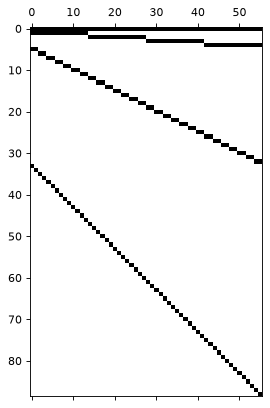

In [7]:
hplot = HierarchicalPlot(S=S_df, tags=tags)
hplot.plot_summing_matrix();

In [8]:
S = S_df.drop(columns='unique_id').to_numpy()
n_series, n_bottom = S.shape
ids = S_df['unique_id'].to_numpy()


def to_matrix(df, col):
    """Long-формат → матрица (ряды в порядке S × моменты времени)."""
    return df.pivot(index='unique_id', columns='ds', values=col).loc[ids].to_numpy()


Y = to_matrix(Y_df, 'y')
B = Y[-n_bottom:]

print('Нижние строки S — единичная матрица:', np.allclose(S[-n_bottom:], np.eye(n_bottom)))
print('y = S·b для всех моментов:', np.allclose(S @ B, Y))

Нижние строки S — единичная матрица: True
y = S·b для всех моментов: True


## 2. Базовые прогнозы и несогласованность

Отложим последние H = 8 кварталов и построим AutoETS по каждому из 89 рядов независимо.
`fitted=True` сохраняет прогнозы на обучении — они понадобятся методам, использующим историю.

In [9]:
cutoff = Y_df['ds'].sort_values().unique()[-H - 1]
Y_train = Y_df[Y_df['ds'] <= cutoff]
Y_test = Y_df[Y_df['ds'] > cutoff]

sf = StatsForecast(models=[AutoETS(season_length=4)], freq='QE', n_jobs=1)
Y_hat = sf.forecast(df=Y_train, h=H, fitted=True)
Y_fitted = sf.forecast_fitted_values()

Y_hat.head()

,unique_id,ds,AutoETS
0,total,2005-03-31,84429.929688
1,total,2005-06-30,66037.890625
2,total,2005-09-30,72271.367188
3,total,2005-12-31,71588.273438
4,total,2006-03-31,84429.929688


Мера несогласованности: насколько прогноз агрегата отличается от суммы прогнозов нижних рядов,
$\hat y - S\,\hat b$, в процентах от прогноза.

In [10]:
Y_hat_mat = to_matrix(Y_hat, 'AutoETS')
gap = Y_hat_mat - S @ Y_hat_mat[-n_bottom:]

incoherence = pd.Series({
    level: 100 * np.abs(gap[np.isin(ids, level_ids)]).mean() / np.abs(Y_hat_mat[np.isin(ids, level_ids)]).mean()
    for level, level_ids in tags.items()
}, name='|ŷ − S·b̂| / |ŷ|, %')
incoherence.round(2)

total                       1.02
total/purpose               2.65
total/purpose/state         3.32
total/purpose/state/area    0.00
Name: |ŷ − S·b̂| / |ŷ|, %, dtype: float64

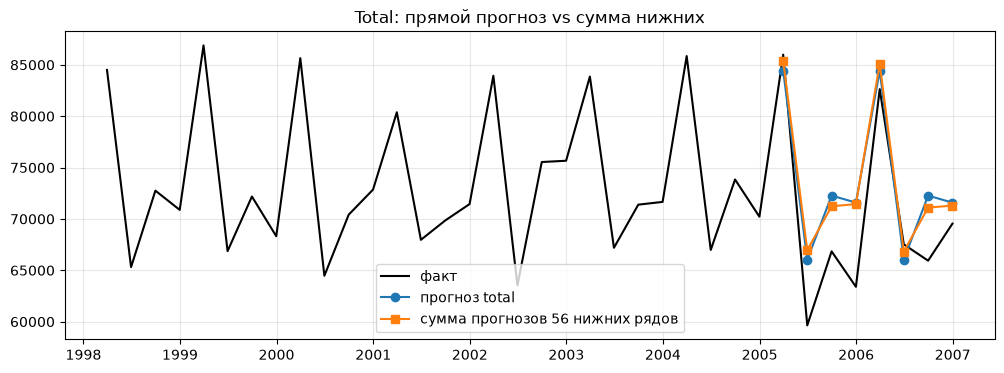

In [11]:
dates_test = np.sort(Y_test['ds'].unique())

plt.plot(wide.index, wide['total'], color='black', label='факт')
plt.plot(dates_test, Y_hat_mat[0], 'o-', label='прогноз total')
plt.plot(dates_test, Y_hat_mat[-n_bottom:].sum(axis=0), 's-', label='сумма прогнозов 56 нижних рядов')
plt.title('Total: прямой прогноз vs сумма нижних')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Самый нижний уровень согласован сам с собой (gap = 0), на всех агрегатах прогноз и сумма нижних расходятся.

## 3. Bottom-up

Прогнозируем только нижние ряды и суммируем: $\tilde y = S\, \hat b$.

- **+** не теряем информацию нижнего уровня (свои тренды и сезонности у каждого ряда);
- **−** нижние ряды шумные, ошибки складываются; на агрегатах часто проигрывает прямому прогнозу.

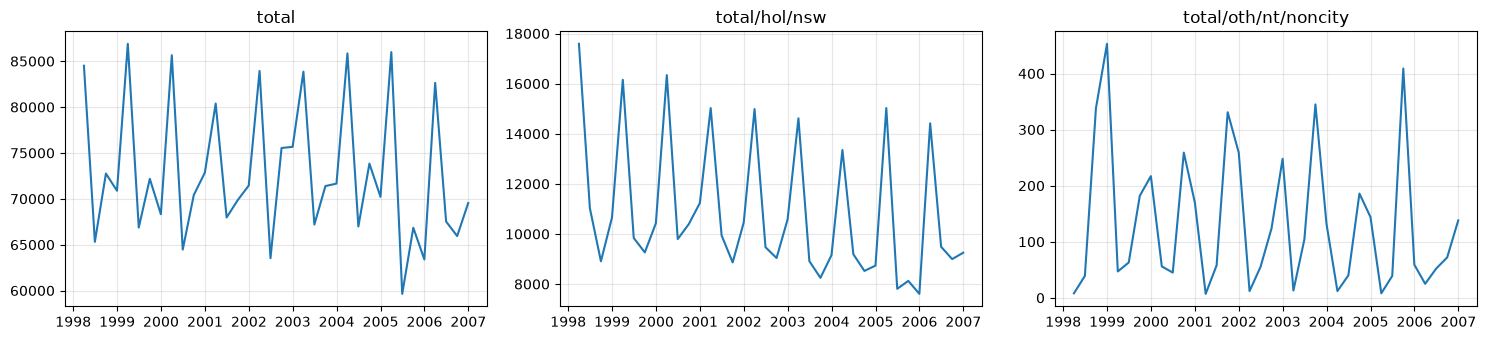

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, uid in zip(axes, ['total', 'total/hol/nsw', 'total/oth/nt/noncity']):
    ax.plot(Y_df.loc[Y_df['unique_id'] == uid, 'ds'], Y_df.loc[Y_df['unique_id'] == uid, 'y'])
    ax.set_title(uid)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Чем ниже уровень, тем меньше значения и тем сильнее шум относительно сигнала.

## 4. Top-down и middle-out

Прогнозируем только total и раздаём его вниз по долям $p_j$: $\tilde b_j = p_j\, \hat y_{total}$.
Три способа посчитать доли:

| метод | доля $p_j$ |
|---|---|
| `average_proportions` | $\frac{1}{T}\sum_t \frac{y_{j,t}}{y_{total,t}}$ — среднее долей |
| `proportion_averages` | $\frac{\bar y_j}{\bar y_{total}}$ — доля средних |
| `forecast_proportions` | доли из базовых прогнозов: на каждом уровне — доля прогноза ряда среди «братьев» |

Первые два способа берут доли из истории, поэтому доли одинаковы на всём горизонте.

In [13]:
train_mat = to_matrix(Y_train, 'y')
y_total = train_mat[0]
b_train = train_mat[-n_bottom:]

p_avg = (b_train / y_total).mean(axis=1)            # average_proportions
p_prop = b_train.mean(axis=1) / y_total.mean()      # proportion_averages

print(f'Сумма долей: {p_avg.sum():.6f}, {p_prop.sum():.6f}')

Сумма долей: 1.000000, 1.000000


**Почему TD смещён.** Исторические доли постоянны, поэтому все нижние ряды получают тренд и сезонность total.
Если у ряда своя сезонность, TD систематически ошибается в одну сторону даже при точном прогнозе total.
Пример — бизнес-поездки в Сидней (NSW, city): у ряда нет пика в I квартале (летние каникулы в Австралии),
а TD переносит на него пик total.

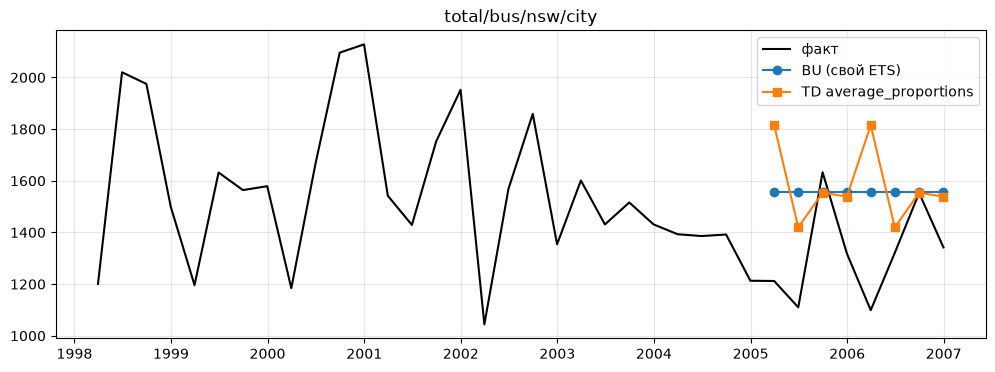

In [14]:
uid = 'total/bus/nsw/city'
j = list(ids[-n_bottom:]).index(uid)

plt.plot(Y_df.loc[Y_df['unique_id'] == uid, 'ds'], Y_df.loc[Y_df['unique_id'] == uid, 'y'], color='black', label='факт')
plt.plot(dates_test, Y_hat_mat[-n_bottom + j], 'o-', label='BU (свой ETS)')
plt.plot(dates_test, p_avg[j] * Y_hat_mat[0], 's-', label='TD average_proportions')
plt.title(uid)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Middle-out** — компромисс: прогнозируем средний уровень (здесь — цель поездки), вверх суммируем (BU),
вниз раздаём по долям (TD).

## 5. Единая формула: $\tilde y = S\, G\, \hat y$

Любой из методов — это матрица $G$ (56 × 89), которая из всех 89 базовых прогнозов делает 56 нижних,
после чего $S$ собирает согласованную иерархию.

- BU: $G = [\,0 \mid I\,]$ — берём только нижние прогнозы;
- TD: $G = [\,p \mid 0\,]$ — берём только total и умножаем на доли.

In [15]:
n_agg = n_series - n_bottom

G_bu = np.hstack([np.zeros((n_bottom, n_agg)), np.eye(n_bottom)])
G_td = np.hstack([p_avg[:, None], np.zeros((n_bottom, n_series - 1))])

Y_bu_manual = S @ G_bu @ Y_hat_mat
Y_td_manual = S @ G_td @ Y_hat_mat

Сверим с `HierarchicalReconciliation`. Методам с историческими долями нужен `Y_df` с фактом на обучении.

In [16]:
reconcilers = [
    BottomUp(),
    TopDown(method='average_proportions'),
    TopDown(method='proportion_averages'),
    TopDown(method='forecast_proportions'),
    MiddleOut(middle_level='total/purpose', top_down_method='forecast_proportions'),
]
hrec = HierarchicalReconciliation(reconcilers=reconcilers)
Y_rec = hrec.reconcile(Y_hat_df=Y_hat, Y_df=Y_fitted, S_df=S_df, tags=tags)

names = {
    'AutoETS': 'Base',
    'AutoETS/BottomUp': 'BU',
    'AutoETS/TopDown_method-average_proportions': 'TD avg_prop',
    'AutoETS/TopDown_method-proportion_averages': 'TD prop_avg',
    'AutoETS/TopDown_method-forecast_proportions': 'TD fcst_prop',
    'AutoETS/MiddleOut_middle_level-total/purpose_top_down_method-forecast_proportions': 'MiddleOut',
}
Y_rec = Y_rec.rename(columns=names)
models = list(names.values())

print('BU руками = библиотека:', np.allclose(Y_bu_manual, to_matrix(Y_rec, 'BU')))
print('TD руками = библиотека:', np.allclose(Y_td_manual, to_matrix(Y_rec, 'TD avg_prop')))

BU руками = библиотека: True
TD руками = библиотека: True


Все методы согласованы: прогноз каждого агрегата равен сумме нижних.

In [17]:
for model in models:
    mat = to_matrix(Y_rec, model)
    print(f'{model:13s} согласован: {np.allclose(mat, S @ mat[-n_bottom:])}')

Base          согласован: False
BU            согласован: True
TD avg_prop   согласован: True
TD prop_avg   согласован: True
TD fcst_prop  согласован: True
MiddleOut     согласован: True


**Весь вопрос в выборе G.** BU и TD — крайние случаи: каждый выбрасывает часть базовых прогнозов.

## 6. Оценка по уровням

`hierarchicalforecast.evaluation.evaluate` считает метрику отдельно на каждом уровне иерархии.
Метрика — MASE с сезонностью 4: ошибки разных рядов сопоставимы, их можно усреднять внутри уровня.

In [18]:
Y_eval = Y_rec.merge(Y_test, on=['unique_id', 'ds'])
evaluation = evaluate(Y_eval, metrics=[partial(mase, seasonality=4)], tags=tags, train_df=Y_train)

table = evaluation.drop(columns='metric').set_index('level')
table.style.format('{:.3f}').highlight_min(axis=1, color='lightgreen')

,Base,BU,TD avg_prop,TD prop_avg,TD fcst_prop,MiddleOut
level,,,,,,
total,1.567,1.436,1.567,1.567,1.567,1.712
total/purpose,1.173,1.248,1.657,1.668,1.112,1.173
total/purpose/state,0.951,0.880,1.210,1.208,0.888,0.912
total/purpose/state/area,0.855,0.855,1.028,1.024,0.852,0.868
Overall,0.908,0.887,1.120,1.117,0.883,0.905


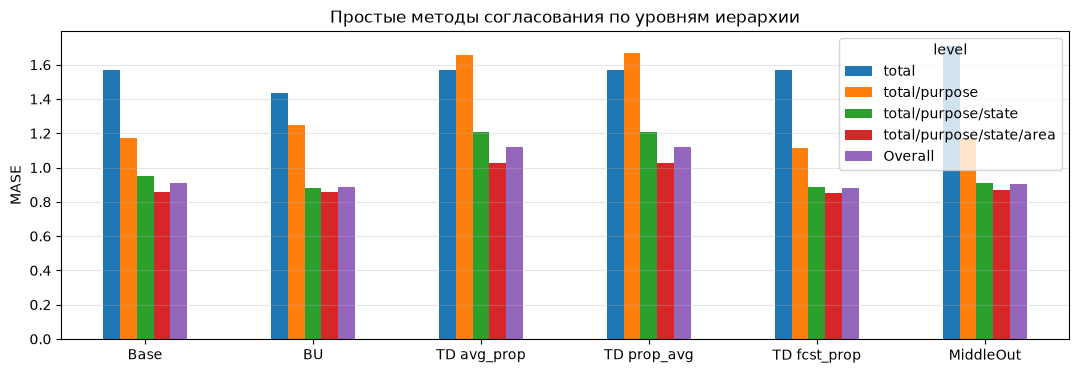

In [19]:
table.T.plot(kind='bar', figsize=(13, 4))
plt.ylabel('MASE')
plt.title('Простые методы согласования по уровням иерархии')
plt.xticks(rotation=0)
plt.grid(alpha=0.3, axis='y')
plt.show()

### Наблюдения

- На total лучший — BU (сумма 56 нижних прогнозов точнее прямого ETS); TD на total по определению совпадает
  с базовым прогнозом, а MiddleOut — с суммой прогнозов по целям, и оба здесь хуже.
- На средних и нижнем уровнях лучший — TD `forecast_proportions`: доли берутся из базовых прогнозов
  и меняются по горизонту.
- TD с историческими долями (`avg_prop`, `prop_avg`) — худший на всех уровнях ниже total: постоянные доли
  не передают собственные тренды и сезонности рядов.
- Единого победителя по всем уровням нет; к тому же у нас одно окно из 8 кварталов, и различия
  в несколько процентов — на уровне шума.

**Вывод:** выбирать одну «правильную» часть базовых прогнозов (низ или верх) — плохая стратегия.
Нужна $G$, которая использует *все* базовые прогнозы, — это оптимальное согласование.

## Итог

| Метод | G использует | Плюсы | Минусы |
|---|---|---|---|
| Bottom-up | только низ | нет потери информации, несмещённый | шумный низ, ошибки суммируются |
| Top-down (исторические доли) | только total | просто, стабильно наверху | смещён: доли постоянны, теряет динамику низа |
| Top-down (`forecast_proportions`) | total + относительные прогнозы | доли меняются по горизонту | всё ещё смещён |
| Middle-out | средний уровень | компромисс BU/TD | выбор уровня — гиперпараметр |

Все методы записываются как $\tilde y = S\,G\,\hat y$ и отличаются только матрицей $G$.